# 02 · Model Design & Regularization
**Owner:** Member 2

Build a baseline ANN, then add L2 + Dropout + Early Stopping and compare.

In [1]:
# ===== SHARED SETUP (same in every notebook — don't change without telling the team) =====
import os, sys

# In Colab: clone the repo and move into it
if "google.colab" in sys.modules:
    REPO_URL = "https://github.com/<OWNER>/insurance-risk-scoring.git"  # <-- set once
    if not os.path.exists("insurance-risk-scoring"):
        !git clone {REPO_URL}
    %cd insurance-risk-scoring
elif os.path.basename(os.getcwd()) == "dev":
    os.chdir("../..")  # running locally from notebooks/dev

import numpy as np
import pandas as pd
import tensorflow as tf

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Paths
RAW_CSV          = "data/raw/Car_Insurance_Claim.csv"
PROCESSED_DIR    = "data/processed"
MODELS_DIR       = "models"
FIGURES_DIR      = "reports/figures"
PREPROCESSOR_PKL = f"{MODELS_DIR}/preprocessor.pkl"
BEST_MODEL       = f"{MODELS_DIR}/best_model.keras"
TARGET           = "OUTCOME"

def load_splits():
    """Load the frozen splits saved by notebook 01."""
    names = ["X_train", "X_val", "X_test", "y_train", "y_val", "y_test"]
    return [np.load(f"{PROCESSED_DIR}/{n}.npy") for n in names]


## 1. Load Splits

In [2]:
import json
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, accuracy_score

X_train, X_val, X_test, y_train, y_val, y_test = load_splits()

# Class weights computed in notebook 01 (claims are the minority class, ~31%)
with open(f"{PROCESSED_DIR}/class_weights.json") as f:
    CLASS_WEIGHT = {int(k): v for k, v in json.load(f).items()}

N_FEATURES = X_train.shape[1]
print("Train:", X_train.shape, "| Val:", X_val.shape, "| Test:", X_test.shape)
print("Claim rate  train=%.3f  val=%.3f" % (y_train.mean(), y_val.mean()))
print("Class weights:", CLASS_WEIGHT)

# NOTE: the test set is NOT used in this notebook. It is reserved for final
# evaluation in notebook 03. All comparisons below use the validation set.

Train: (5703, 23) | Val: (1223, 23) | Test: (1223, 23)
Claim rate  train=0.311  val=0.312
Class weights: {0: 0.7257571901247136, 1: 1.6073844419391206}


## 2. Baseline ANN

**Design choices**
- **Input:** 23 features from notebook 01 (numeric columns already standardised, categorical columns encoded).
- **Hidden layers:** 2 Dense layers (64 → 32) with **ReLU**. That is enough capacity for ~5.7k training rows of tabular data; a deeper network would only overfit faster.
- **Output:** 1 neuron with **sigmoid**, which gives the claim probability (0–1).
- **Loss / optimizer:** binary cross-entropy with Adam (lr = 0.001).
- **Class imbalance:** only ~31% of customers claim, so we pass the `class_weight` from notebook 01. Without it the model under-predicts claims and recall drops.
- **Metrics tracked:** ROC-AUC (main metric, independent of the threshold), Precision and Recall.

`build_model()` takes `l2` and `dropout` arguments, so the baseline and the regularized model share **exactly the same architecture and starting weights**. The only difference between them is the regularization.

In [3]:
EPOCHS     = 150   # long on purpose: lets the baseline overfit so the effect is visible
BATCH_SIZE = 32
LR         = 1e-3

def build_model(units=(64, 32), l2=0.0, dropout=0.0, lr=LR, name="ann"):
    """Feed-forward ANN for binary classification.

    units   : neurons in each hidden layer
    l2      : L2 weight penalty on every hidden Dense layer (0 = off)
    dropout : dropout rate after every hidden layer (0 = off)
    """
    tf.keras.utils.set_random_seed(SEED)  # same initial weights for every run -> fair comparison
    reg = regularizers.l2(l2) if l2 > 0 else None

    model = keras.Sequential(name=name)
    model.add(keras.Input(shape=(N_FEATURES,)))
    for u in units:
        model.add(layers.Dense(u, activation="relu", kernel_regularizer=reg))
        if dropout > 0:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1, activation="sigmoid"))  # claim probability

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss="binary_crossentropy",
        metrics=[keras.metrics.AUC(name="auc"),
                 keras.metrics.Precision(name="precision"),
                 keras.metrics.Recall(name="recall")],
    )
    return model

baseline = build_model(name="baseline_ann")
baseline.summary()

Model: "baseline_ann"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,649 (14.25 KB)

 Trainable params: 3,649 (14.25 KB)

 Non-trainable params: 0 (0.00 B)

## 3. Train & Learning Curves

Baseline: lowest val_loss at epoch 11, final train_loss=0.134, val_loss=0.681


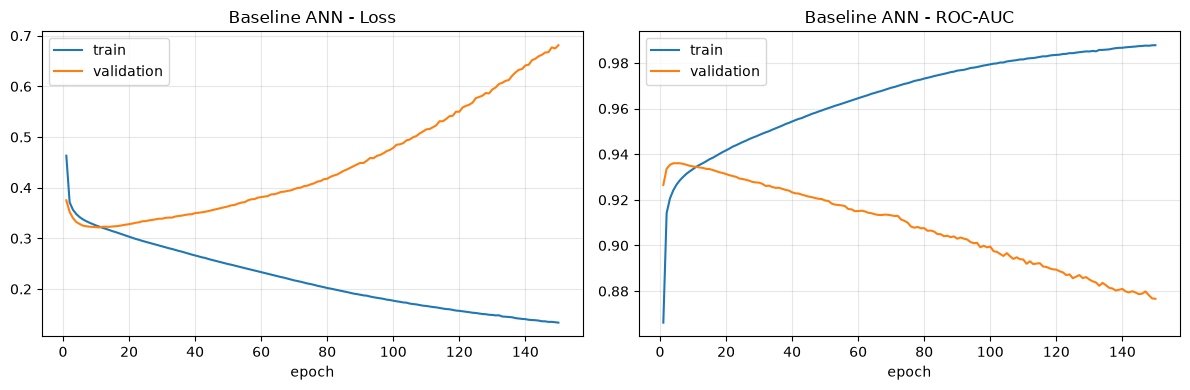

In [4]:
def train(model, callbacks=None, epochs=EPOCHS):
    return model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=epochs, batch_size=BATCH_SIZE,
        class_weight=CLASS_WEIGHT,   # counter the class imbalance
        callbacks=callbacks or [], verbose=0,
    )

def plot_curves(history, title, ax_pair, stop_epoch=None):
    h = history.history
    ep = range(1, len(h["loss"]) + 1)
    for ax, metric, label in [(ax_pair[0], "loss", "Loss"), (ax_pair[1], "auc", "ROC-AUC")]:
        ax.plot(ep, h[metric], label="train")
        ax.plot(ep, h[f"val_{metric}"], label="validation")
        if stop_epoch:
            ax.axvline(stop_epoch, color="gray", ls="--", lw=1, label=f"best epoch ({stop_epoch})")
        ax.set_title(f"{title} - {label}"); ax.set_xlabel("epoch"); ax.legend(); ax.grid(alpha=.3)

hist_base = train(baseline)

best_ep = int(np.argmin(hist_base.history["val_loss"])) + 1
print(f"Baseline: lowest val_loss at epoch {best_ep}, "
      f"final train_loss={hist_base.history['loss'][-1]:.3f}, val_loss={hist_base.history['val_loss'][-1]:.3f}")

fig_base, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_curves(hist_base, "Baseline ANN", axes)
plt.tight_layout(); plt.show()

## 4. Regularized ANN (L2, Dropout, EarlyStopping)

| Technique | Setting | What it does |
|---|---|---|
| **L2 (weight decay)** | λ = 0.001 on every hidden layer | Adds λ·Σw² to the loss, which keeps weights small so the model cannot fit noise with extreme weights |
| **Dropout** | rate = 0.3 after every hidden layer | Randomly switches off 30% of neurons on each training step, so the network cannot rely on any single neuron |
| **Early Stopping** | monitor `val_loss`, patience 15, `restore_best_weights=True` | Stops training once validation loss stops improving and rolls back to the best epoch |

To show what each technique contributes, we also train **L2 only** and **Dropout only** (no early stopping), then the **full combination**.

## 4. Regularized ANN (L2, Dropout, EarlyStopping)

L2 only                    trained 150 epochs


Dropout only               trained 150 epochs


L2 + Dropout + EarlyStop   trained 56 epochs

EarlyStopping restored weights from epoch 41


Model: "l2__dropout__earlystop"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ (None, 64)             │         1,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,949 (42.77 KB)

 Trainable params: 3,649 (14.25 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 7,300 (28.52 KB)

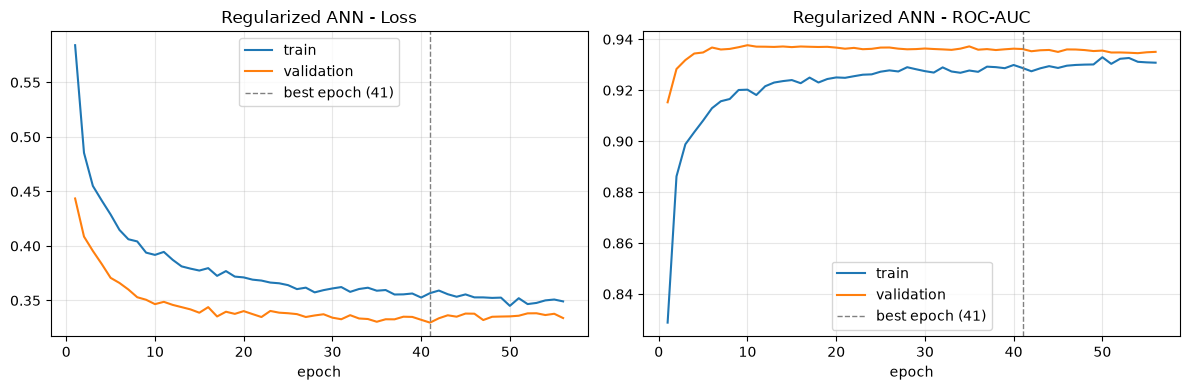

In [5]:
L2      = 1e-3
DROPOUT = 0.3

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=15, restore_best_weights=True, verbose=0)

# Ablation: add each technique on its own, then all together, so we can see what each one does.
# L2-only and Dropout-only runs use no EarlyStopping (full EPOCHS) to isolate their effect.
experiments = {
    "L2 only":               dict(l2=L2,  dropout=0.0),
    "Dropout only":          dict(l2=0.0, dropout=DROPOUT),
    "L2 + Dropout + EarlyStop": dict(l2=L2, dropout=DROPOUT, early_stop=True),
}

models, histories = {"Baseline": baseline}, {"Baseline": hist_base}
for name, cfg in experiments.items():
    m = build_model(l2=cfg["l2"], dropout=cfg["dropout"], name=name.replace(" ", "_").replace("+", "").lower())
    histories[name] = train(m, callbacks=[early_stop] if cfg.get("early_stop") else None)
    models[name] = m
    print(f"{name:26s} trained {len(histories[name].history['loss'])} epochs")

regularized = models["L2 + Dropout + EarlyStop"]
hist_reg = histories["L2 + Dropout + EarlyStop"]
reg_best_ep = int(np.argmin(hist_reg.history["val_loss"])) + 1
print(f"\nEarlyStopping restored weights from epoch {reg_best_ep}")
regularized.summary()

fig_reg, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_curves(hist_reg, "Regularized ANN", axes, stop_epoch=reg_best_ep)
plt.tight_layout(); plt.show()

## 5. Baseline vs Regularized Comparison

### Conclusions (validation set)

| Model | Precision | Recall | F1 | ROC-AUC | Train–Val AUC gap |
|---|---|---|---|---|---|
| Baseline | 0.697 | 0.774 | 0.734 | 0.889 | 0.099 |
| L2 only | 0.670 | 0.864 | 0.755 | 0.915 | 0.049 |
| Dropout only | 0.701 | 0.843 | 0.765 | 0.919 | 0.046 |
| **L2 + Dropout + EarlyStop** | **0.743** | 0.835 | **0.786** | **0.936** | **0.001** |

- **Every regularization technique helps.** L2 alone and Dropout alone each cut the overfitting gap roughly in half and raise validation ROC-AUC by ~0.03.
- **The combination works best.** It has the highest ROC-AUC (0.936), F1 (0.786) and precision, and the train–validation gap almost disappears (0.001). Early stopping ended training at epoch 56 and restored the weights from **epoch 41**.
- **Why validation loss is below training loss in the regularized curves:** dropout and the L2 penalty are active only during training, which makes training loss look worse. At evaluation time the full network is used without the penalty. This is expected, not a bug.
- **Hand-off to notebook 03:** the 64→32 network with L2 = 0.001, Dropout = 0.3 and EarlyStopping is the starting point for Keras Tuner. These settings are saved in `models/regularized_config.json`. The final test-set evaluation happens in notebook 03.

_Numbers come from the run with `SEED = 42`; small differences on another machine are normal._

,val_Accuracy,val_Precision,val_Recall,val_F1,val_ROC-AUC,train_AUC,AUC gap (train-val),min val_loss,final val_loss,epochs
Model,,,,,,,,,,
Baseline,0.8250,0.6974,0.7743,0.7338,0.8888,0.9880,0.0992,0.3215,0.6813,150
L2 only,0.8250,0.6701,0.8635,0.7546,0.9150,0.9644,0.0494,0.3477,0.4285,150
Dropout only,0.8389,0.7009,0.8425,0.7652,0.9188,0.9644,0.0457,0.3084,0.3664,150
L2 + Dropout + EarlyStop,0.8585,0.7430,0.8346,0.7862,0.9361,0.9374,0.0013,0.3297,0.3339,56


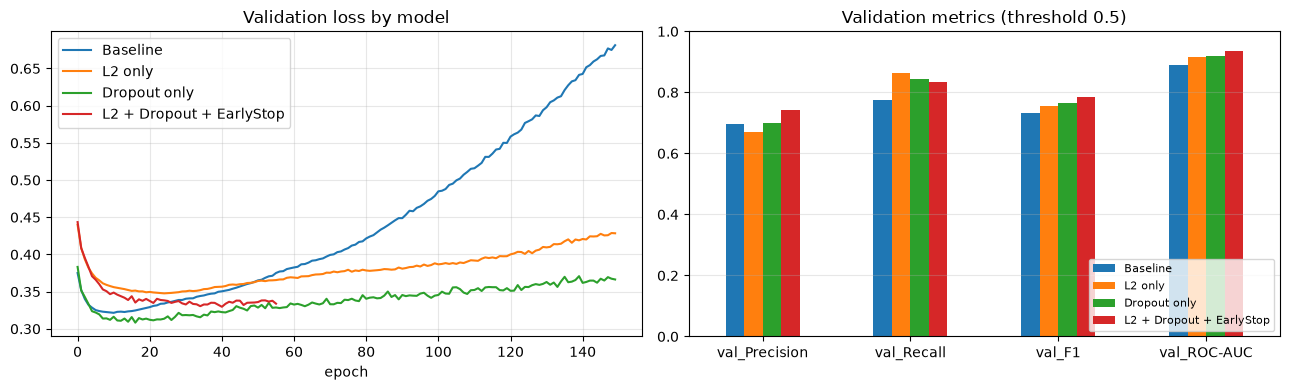

In [6]:
def evaluate(model, X, y, threshold=0.5):
    p = model.predict(X, verbose=0).ravel()
    yhat = (p >= threshold).astype(int)
    return {
        "Accuracy":  accuracy_score(y, yhat),
        "Precision": precision_score(y, yhat, zero_division=0),
        "Recall":    recall_score(y, yhat),
        "F1":        f1_score(y, yhat),
        "ROC-AUC":   roc_auc_score(y, p),
    }

rows = []
for name, m in models.items():
    tr, va = evaluate(m, X_train, y_train), evaluate(m, X_val, y_val)
    h = histories[name].history
    rows.append({"Model": name, **{f"val_{k}": v for k, v in va.items()},
                 "train_AUC": tr["ROC-AUC"],
                 "AUC gap (train-val)": tr["ROC-AUC"] - va["ROC-AUC"],
                 "min val_loss": min(h["val_loss"]),
                 "final val_loss": h["val_loss"][-1],
                 "epochs": len(h["loss"])})

comparison = pd.DataFrame(rows).set_index("Model").round(4)
display(comparison)

# Overlay: validation loss of every model on one plot
fig_cmp, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, h in histories.items():
    axes[0].plot(h.history["val_loss"], label=name)
axes[0].set_title("Validation loss by model"); axes[0].set_xlabel("epoch"); axes[0].legend(); axes[0].grid(alpha=.3)

metrics = ["val_Precision", "val_Recall", "val_F1", "val_ROC-AUC"]
comparison[metrics].T.plot.bar(ax=axes[1], rot=0)
axes[1].set_title("Validation metrics (threshold 0.5)"); axes[1].set_ylim(0, 1)
axes[1].legend(fontsize=8, loc="lower right"); axes[1].grid(alpha=.3, axis="y")
plt.tight_layout(); plt.show()

## 6. Save Plots to `reports/figures/`

In [7]:
os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

fig_base.savefig(f"{FIGURES_DIR}/07_baseline_learning_curves.png",    dpi=150, bbox_inches="tight")
fig_reg.savefig(f"{FIGURES_DIR}/08_regularized_learning_curves.png",  dpi=150, bbox_inches="tight")
fig_cmp.savefig(f"{FIGURES_DIR}/09_baseline_vs_regularized.png",      dpi=150, bbox_inches="tight")
comparison.to_csv("reports/02_model_comparison.csv")

# Saved for reference / the final notebook. The model used for inference is still
# best_model.keras from notebook 03.
baseline.save(f"{MODELS_DIR}/baseline_model.keras")
regularized.save(f"{MODELS_DIR}/regularized_model.keras")

# Settings handed to notebook 03 as a starting point for tuning
handoff = {"units": [64, 32], "l2": L2, "dropout": DROPOUT, "learning_rate": LR,
           "batch_size": BATCH_SIZE, "early_stopping": {"monitor": "val_loss", "patience": 15},
           "best_epoch": reg_best_ep}
with open(f"{MODELS_DIR}/regularized_config.json", "w") as f:
    json.dump(handoff, f, indent=2)

print("Saved figures 07-09, reports/02_model_comparison.csv, baseline/regularized models and config.")

Saved figures 07-09, reports/02_model_comparison.csv, baseline/regularized models and config.
